# DSA 4060XA – Week 6 Guided Evaluation Lab
## Evaluating Recommender Systems
**Name:** Sean  |  **Student ID:** 669648

Popularity baseline, content-based filtering and item-based collaborative filtering, compared on rating prediction (MAE, RMSE), ranking (Precision@K, Recall@K, NDCG@K) and beyond-accuracy measures (coverage, novelty, diversity).

## Step 1 – Import the Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity

TOP_K = 3

## Step 2 – Load and Inspect the Data

In [2]:
movies = pd.read_csv("DSA4060_Week6_Movies.csv")
ratings = pd.read_csv("DSA4060_Week6_Ratings.csv")

display(movies.head())
display(ratings.head())

print("Users:", ratings["user_id"].nunique())
print("Movies:", ratings["movie_id"].nunique())
print("Ratings:", len(ratings))

,movie_id,title,genres
0,1,Galaxy Mission,Action|Sci-Fi
1,2,Love in Nairobi,Romance|Drama
2,3,Final Battle,Action
3,4,Family Weekend,Comedy|Family
4,5,Future World,Sci-Fi|Action


,user_id,movie_id,rating,timestamp
0,1,2,3,1
1,1,10,3,2
2,1,1,5,3
3,1,9,3,4
4,1,7,3,5


Users: 12
Movies: 20
Ratings: 120


**Student Check**

1. One row in `movies` is one movie: its `movie_id`, `title` and a pipe-separated list of `genres` (item metadata).
2. One row in `ratings` is one user's rating of one movie, with a `timestamp` showing the order in which the user rated it.
3. There are 12 unique users and 20 unique movies, with 120 ratings in total (every user rated 10 movies).
4. The rating column is explicit feedback, because users directly state how much they liked a movie.
5. The scale is 1–5 stars. In this data the lowest rating actually used is 2 and the highest is 5.

## Step 3 – Inspect Rating Behaviour

In [3]:
ratings["rating"].value_counts().sort_index()

rating
2    29
3    49
4    28
5    14
Name: count, dtype: int64

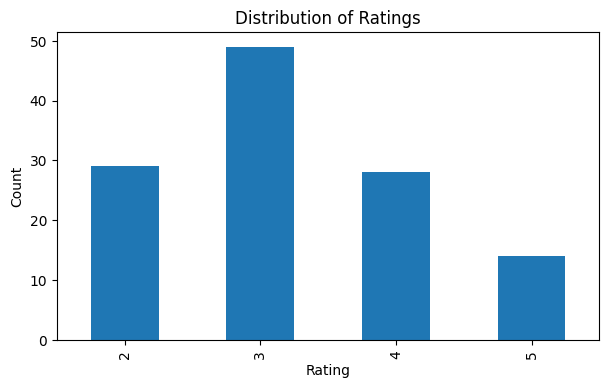

In [4]:
plt.figure(figsize=(7,4))
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

**Interpretation:** Middle ratings dominate. A rating of 3 is the most common (49 of 120), followed by 2 (29) and 4 (28), while 5 is fairly rare (14) and there are no 1-star ratings. Only 42 of the 120 ratings (35%) are 4 or 5, so "relevant" items are scarce. This matters for evaluation because a model that just predicts something near 3 will already get a respectable MAE, and ranking metrics will be based on very few relevant items.

## Step 4 – Create a Train/Test Split

In [5]:
ratings = ratings.sort_values(["user_id", "timestamp"])

test = ratings.groupby("user_id").tail(1).copy()
train = ratings.drop(test.index).copy()

print("Training interactions:", len(train))
print("Test interactions:", len(test))
display(test.head())

Training interactions: 108
Test interactions: 12


,user_id,movie_id,rating,timestamp
9,1,14,4,10
19,2,9,4,20
29,3,18,3,30
39,4,18,3,40
49,5,11,2,50


Each user's most recent rating is held out (12 test rows, 108 training rows). This is a time-based split, so the model only learns from the past and is tested on something it has not seen. If we evaluated on interactions the model already trained on, the results would look better than they really are.

## Step 5 – Build a Popularity Baseline

In [6]:
global_mean = train["rating"].mean()

movie_stats = (
    train.groupby("movie_id")
    .agg(
        mean_rating=("rating", "mean"),
        rating_count=("rating", "size")
    )
    .reset_index()
    .merge(movies[["movie_id", "title"]], on="movie_id")
)

movie_stats.sort_values(
    ["mean_rating", "rating_count"],
    ascending=[False, False]
).head(10)

,movie_id,mean_rating,rating_count,title
5,6,4.166667,6,Broken Hearts
0,1,4.000000,3,Galaxy Mission
17,18,4.000000,2,The Promise
3,4,3.800000,5,Family Weekend
9,10,3.666667,6,Hidden Truth
15,16,3.571429,7,Campus Life
6,7,3.500000,8,City Detectives
12,13,3.400000,5,Digital Dreams
18,19,3.250000,4,Night Chase
2,3,3.166667,6,Final Battle


In [7]:
movie_mean_map = train.groupby("movie_id")["rating"].mean().to_dict()

baseline_test = test.copy()
baseline_test["prediction"] = baseline_test["movie_id"].map(movie_mean_map)
baseline_test["prediction"] = baseline_test["prediction"].fillna(global_mean)

## Step 6 – Evaluate the Baseline with MAE and RMSE

In [8]:
def rating_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

baseline_mae, baseline_rmse = rating_metrics(
    baseline_test["rating"],
    baseline_test["prediction"]
)

print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE: 1.086
Baseline RMSE: 1.201


**Interpretation:** The baseline MAE is about 1.09, so on average it is wrong by roughly one rating point. RMSE is a bit higher (about 1.20) because it punishes the larger misses more.

## Step 7 – Build Item Features for Content-Based Filtering

In [9]:
genre_features = movies["genres"].str.get_dummies(sep="|")

content_items = pd.concat(
    [movies[["movie_id", "title"]], genre_features],
    axis=1
)

genre_columns = genre_features.columns.tolist()
item_feature_matrix = content_items.set_index("movie_id")[genre_columns]

display(content_items.head())

,movie_id,title,Action,Adventure,Comedy,Crime,Drama,Family,Mystery,Romance,Sci-Fi
0,1,Galaxy Mission,1,0,0,0,0,0,0,0,1
1,2,Love in Nairobi,0,0,0,0,1,0,0,1,0
2,3,Final Battle,1,0,0,0,0,0,0,0,0
3,4,Family Weekend,0,0,1,0,0,1,0,0,0
4,5,Future World,1,0,0,0,0,0,0,0,1


## Step 8 – Build a User Preference Profile

In [10]:
def build_user_profile(user_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    ids = history["movie_id"].values
    ratings_array = history["rating"].values.reshape(-1, 1)
    features = item_feature_matrix.loc[ids].values
    return (features * ratings_array).mean(axis=0)

profile = build_user_profile(1, train)

pd.Series(
    profile,
    index=genre_columns
).sort_values(ascending=False)

Drama        1.666667
Sci-Fi       1.000000
Comedy       0.888889
Romance      0.666667
Action       0.555556
Family       0.555556
Crime        0.333333
Mystery      0.333333
Adventure    0.222222
dtype: float64

In [11]:
# Supporting view: what User 1 actually rated in training
train[train["user_id"] == 1].merge(movies, on="movie_id")[["title", "genres", "rating"]]

,title,genres,rating
0,Love in Nairobi,Romance|Drama,3
1,Hidden Truth,Drama|Mystery,3
2,Galaxy Mission,Action|Sci-Fi,5
3,Wedding Weekend,Romance|Comedy,3
4,City Detectives,Crime|Drama,3
5,Home Again,Family|Drama,2
6,Digital Dreams,Sci-Fi|Drama,4
7,Weekend Escape,Comedy|Adventure,2
8,Family Weekend,Comedy|Family,3


**Student task:** User 1's two strongest genres are **Drama (1.67)** and **Sci-Fi (1.00)**. Sci-Fi agrees well with the user's behaviour: their two best-rated movies are Galaxy Mission (5, Action|Sci-Fi) and Digital Dreams (4, Sci-Fi|Drama). Drama is only partly in agreement. It scores highest mostly because five of the nine rated movies carry the Drama tag, but those were rated 2–4 (mostly 3), so the profile rewards how often a genre appears and not only how much the user liked it.

## Step 9 – Content-Based Rating Prediction

In [12]:
def content_score(user_id, movie_id, train_data):
    profile = build_user_profile(user_id, train_data).reshape(1, -1)
    item_vec = item_feature_matrix.loc[movie_id].values.reshape(1, -1)
    sim = cosine_similarity(profile, item_vec)[0, 0]
    return float(np.clip(1 + 4 * sim, 1, 5))

content_test = test.copy()
content_test["prediction"] = content_test.apply(
    lambda r: content_score(r["user_id"], r["movie_id"], train),
    axis=1
)

content_mae, content_rmse = rating_metrics(
    content_test["rating"],
    content_test["prediction"]
)

print("Content MAE:", round(content_mae, 3))
print("Content RMSE:", round(content_rmse, 3))

Content MAE: 1.094
Content RMSE: 1.381


## Step 10 – Build Item-Based Collaborative Filtering

In [13]:
user_item = train.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

item_user = user_item.T.fillna(0)

item_similarity = pd.DataFrame(
    cosine_similarity(item_user),
    index=item_user.index,
    columns=item_user.index
)

item_similarity.iloc[:5, :5]

movie_id,1,2,3,4,5
movie_id,,,,,
1,1.000000,0.314450,0.391983,0.440908,0.132518
2,0.314450,1.000000,0.645526,0.569308,0.543524
3,0.391983,0.645526,1.000000,0.509175,0.196760
4,0.440908,0.569308,0.509175,1.000000,0.468868
5,0.132518,0.543524,0.196760,0.468868,1.000000


## Step 11 – Item-Based Rating Prediction

In [14]:
def item_cf_predict(user_id, movie_id, train_data):
    history = train_data[train_data["user_id"] == user_id]
    weighted_sum = 0.0
    similarity_sum = 0.0

    for row in history.itertuples():
        if movie_id in item_similarity.index and row.movie_id in item_similarity.columns:
            sim = item_similarity.loc[movie_id, row.movie_id]
            if sim > 0:
                weighted_sum += sim * row.rating
                similarity_sum += sim

    if similarity_sum == 0:
        return global_mean

    return weighted_sum / similarity_sum

cf_test = test.copy()
cf_test["prediction"] = cf_test.apply(
    lambda r: item_cf_predict(r["user_id"], r["movie_id"], train),
    axis=1
)

cf_mae, cf_rmse = rating_metrics(
    cf_test["rating"],
    cf_test["prediction"]
)

print("CF MAE:", round(cf_mae, 3))
print("CF RMSE:", round(cf_rmse, 3))

CF MAE: 0.924
CF RMSE: 1.07


## Step 12 – Compare Rating Prediction Metrics

In [15]:
rating_results = pd.DataFrame({
    "Model": [
        "Popularity Baseline",
        "Content-Based",
        "Item-Based CF"
    ],
    "MAE": [baseline_mae, content_mae, cf_mae],
    "RMSE": [baseline_rmse, content_rmse, cf_rmse]
})

rating_results.sort_values("MAE")

,Model,MAE,RMSE
2,Item-Based CF,0.924315,1.069675
0,Popularity Baseline,1.085913,1.201011
1,Content-Based,1.093920,1.380701


6. **Lowest MAE:** Item-Based CF (about 0.92), then the baseline (1.09), then Content-Based (1.09, very slightly worse).
7. **Lowest RMSE:** Item-Based CF (about 1.07), then the baseline (1.20), then Content-Based (1.38).
8. **Does either advanced model beat the baseline?** Only item-based CF does, and only modestly (MAE down by about 15%, RMSE by about 11%). Content-based is no better than the baseline on MAE and clearly worse on RMSE, which means it makes some big misses. Since the test set is just 12 ratings, even the CF win is not strong evidence.
9. **Why not use one metric?** Each metric only shows one side of performance. MAE and RMSE can even disagree, as they do for content-based (tied with the baseline on MAE but much worse on RMSE). More importantly, rating accuracy says nothing about whether the top of a ranked list is useful, which we check next.

## Step 13 – Move from Rating Prediction to Ranking Evaluation

In [16]:
test["relevant"] = test["rating"] >= 4
test[["user_id", "movie_id", "rating", "relevant"]].head()

,user_id,movie_id,rating,relevant
9,1,14,4,True
19,2,9,4,True
29,3,18,3,False
39,4,18,3,False
49,5,11,2,False


In [17]:
print("Relevant test items:", int(test["relevant"].sum()), "out of", len(test))

Relevant test items: 5 out of 12


## Step 14 – Build Top-N Recommendation Functions

In [18]:
all_movie_ids = movies["movie_id"].tolist()

def unseen_movies(user_id):
    seen = set(
        train.loc[train["user_id"] == user_id, "movie_id"]
    )
    return [m for m in all_movie_ids if m not in seen]

popularity_order = (
    movie_stats
    .sort_values(["mean_rating", "rating_count"], ascending=[False, False])
    ["movie_id"].tolist()
)

def recommend_popularity(user_id, k=3):
    unseen = set(unseen_movies(user_id))
    return [m for m in popularity_order if m in unseen][:k]

def recommend_content(user_id, k=3):
    scored = [(m, content_score(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

def recommend_cf(user_id, k=3):
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

print("Popularity:", recommend_popularity(1))
print("Content:", recommend_content(1))
print("Collaborative:", recommend_cf(1))

Popularity: [6, 18, 16]
Content: [16, 6, 18]
Collaborative: [12, 11, 18]


In [19]:
# Same lists with titles, easier to read
title_map = movies.set_index("movie_id")["title"].to_dict()
for name, fn in [("Popularity", recommend_popularity), ("Content", recommend_content), ("Collaborative", recommend_cf)]:
    print(name, "->", [title_map[m] for m in fn(1)])

Popularity -> ['Broken Hearts', 'The Promise', 'Campus Life']
Content -> ['Campus Life', 'Broken Hearts', 'The Promise']


Collaborative -> ['The Last Case', 'Laugh Out Loud', 'The Promise']


**Discussion:** For User 1, popularity and content-based return the same three movies (6, 18, 16), just in a different order, so the content model is not adding much personalization here. Item-based CF gives a clearly different list (12, 11, 18), so it looks the most personalized. Popularity is the easiest to explain ("these are the highest-rated movies you haven't seen"), and content-based is also easy to justify through genres. CF is the hardest to explain because the reason is hidden inside the item similarity matrix.

## Step 15 – Precision@K, Recall@K, and NDCG@K

In [20]:
def precision_recall_at_k(recs, relevant, k):
    recs = recs[:k]
    hits = len(set(recs) & set(relevant))
    precision = hits / k
    recall = hits / len(relevant) if relevant else np.nan
    return precision, recall

def ndcg_at_k(recs, relevant, k):
    dcg = 0.0
    for rank, movie_id in enumerate(recs[:k], start=1):
        if movie_id in relevant:
            dcg += 1 / np.log2(rank + 1)
    ideal_hits = min(len(relevant), k)
    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )
    return dcg / idcg if idcg > 0 else np.nan

def evaluate_ranking(recommender, k=3):
    rows = []
    for user_id in sorted(test["user_id"].unique()):
        relevant = test.loc[
            (test["user_id"] == user_id) &
            (test["rating"] >= 4),
            "movie_id"
        ].tolist()
        if not relevant:
            continue
        recs = recommender(user_id, k)
        precision, recall = precision_recall_at_k(recs, relevant, k)
        rows.append({
            "user_id": user_id,
            "Precision@K": precision,
            "Recall@K": recall,
            "NDCG@K": ndcg_at_k(recs, relevant, k)
        })
    result = pd.DataFrame(rows)
    return {
        "Precision@3": result["Precision@K"].mean(),
        "Recall@3": result["Recall@K"].mean(),
        "NDCG@3": result["NDCG@K"].mean()
    }

pop_rank = evaluate_ranking(recommend_popularity, TOP_K)
content_rank = evaluate_ranking(recommend_content, TOP_K)
cf_rank = evaluate_ranking(recommend_cf, TOP_K)

ranking_results = pd.DataFrame([
    {"Model": "Popularity Baseline", **pop_rank},
    {"Model": "Content-Based", **content_rank},
    {"Model": "Item-Based CF", **cf_rank}
])

ranking_results

,Model,Precision@3,Recall@3,NDCG@3
0,Popularity Baseline,0.066667,0.2,0.1
1,Content-Based,0.066667,0.2,0.2
2,Item-Based CF,0.000000,0.0,0.0


**Interpretation:** Only 5 of the 12 users have a relevant (rating 4–5) held-out movie, so these metrics are averages over 5 users. Because each of those users has exactly one relevant item, the best possible Precision@3 is 0.33. Popularity and content-based both find one of the five relevant movies (Precision@3 = 0.067, Recall@3 = 0.20), but content-based places its hit higher in the list, so its NDCG@3 is 0.20 versus 0.10 for popularity. Item-based CF finds none (all zeros), even though it had the best MAE and RMSE. So the best rating predictor was the worst ranker here.

## Step 16 – Catalogue Coverage

In [21]:
def catalogue_coverage(recommender, k=3):
    recommended = set()
    for user_id in train["user_id"].unique():
        recommended.update(recommender(user_id, k))
    return len(recommended) / movies["movie_id"].nunique()

coverage_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Coverage": [
        catalogue_coverage(recommend_popularity),
        catalogue_coverage(recommend_content),
        catalogue_coverage(recommend_cf)
    ]
})

coverage_results

,Model,Coverage
0,Popularity Baseline,0.35
1,Content-Based,0.70
2,Item-Based CF,0.85


## Step 17 – Novelty

In [22]:
pop_counts = train["movie_id"].value_counts().to_dict()
num_users = train["user_id"].nunique()

def novelty_of_item(movie_id):
    p = pop_counts.get(movie_id, 1) / num_users
    return -np.log2(p)

def average_novelty(recommender, k=3):
    values = []
    for user_id in train["user_id"].unique():
        recs = recommender(user_id, k)
        values.extend([novelty_of_item(m) for m in recs])
    return np.mean(values)

novelty_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Novelty": [
        average_novelty(recommend_popularity),
        average_novelty(recommend_content),
        average_novelty(recommend_cf)
    ]
})

novelty_results

,Model,Novelty
0,Popularity Baseline,1.689432
1,Content-Based,1.343556
2,Item-Based CF,1.694791


## Step 18 – Diversity

In [23]:
genre_similarity = pd.DataFrame(
    cosine_similarity(item_feature_matrix),
    index=item_feature_matrix.index,
    columns=item_feature_matrix.index
)

def list_diversity(movie_ids):
    sims = []
    for i in range(len(movie_ids)):
        for j in range(i + 1, len(movie_ids)):
            sims.append(
                genre_similarity.loc[movie_ids[i], movie_ids[j]]
            )
    return 1 - np.mean(sims) if sims else 0

def average_diversity(recommender, k=3):
    return np.mean([
        list_diversity(recommender(user_id, k))
        for user_id in train["user_id"].unique()
    ])

diversity_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Diversity": [
        average_diversity(recommend_popularity),
        average_diversity(recommend_content),
        average_diversity(recommend_cf)
    ]
})

diversity_results

,Model,Diversity
0,Popularity Baseline,0.736111
1,Content-Based,0.541667
2,Item-Based CF,0.780161


## Step 19 – Build a Unified Evaluation Table

In [24]:
summary = (
    rating_results
    .merge(ranking_results, on="Model")
    .merge(coverage_results, on="Model")
    .merge(novelty_results, on="Model")
    .merge(diversity_results, on="Model")
)

summary.round(3)

,Model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,Coverage,Novelty,Diversity
0,Popularity Baseline,1.086,1.201,0.067,0.2,0.1,0.35,1.689,0.736
1,Content-Based,1.094,1.381,0.067,0.2,0.2,0.70,1.344,0.542
2,Item-Based CF,0.924,1.070,0.000,0.0,0.0,0.85,1.695,0.780


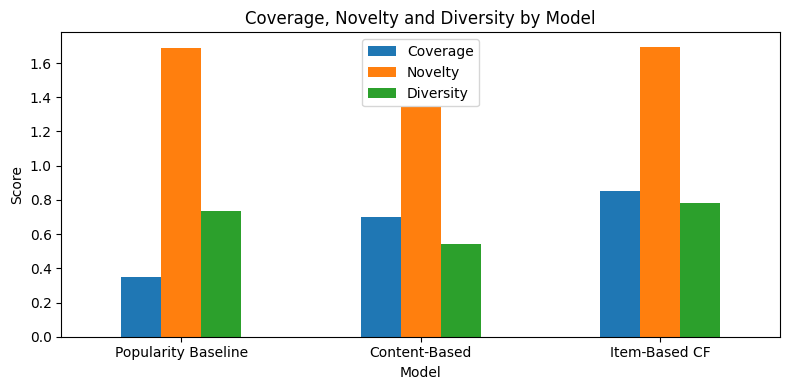

In [25]:
# Quick visual comparison of the beyond-accuracy measures
summary.set_index("Model")[["Coverage", "Novelty", "Diversity"]].plot(kind="bar", figsize=(8,4))
plt.title("Coverage, Novelty and Diversity by Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Findings for coverage, novelty and diversity:**
- **Coverage:** Item-based CF is highest (0.85, so 17 of 20 movies appear in someone's list), content-based is 0.70 and popularity is only 0.35. Popularity is low because everyone gets almost the same top-rated unseen movies.
- **Novelty:** CF (1.69) and popularity (1.69) are about equal, and content-based is lowest (1.34), so content-based leans toward the more commonly rated movies.
- **Diversity:** CF is most diverse within a list (0.78), popularity is close (0.74), and content-based is clearly lowest (0.54) because it keeps recommending movies with similar genres to the user's profile.

## Step 20 – Interpret Evaluation Trade-Offs

This lab shows several of the trade-offs listed in the brief. Item-based CF has the best MAE and RMSE and the best coverage, novelty and diversity, but it got zero ranking hits, so better rating accuracy did not translate into a better Top-3 list. Content-based has the best NDCG (tied precision and recall with popularity) but the lowest diversity and novelty, so its lists are relevant-ish but narrow. Popularity is the simplest and easiest to explain but has the lowest coverage, because it pushes the same few titles to everyone. There is no single best model, and the right choice depends on what the business wants.

## Step 21 – Final Business Scenario

> "We want users to discover relevant movies, but we do not want the same popular titles to dominate every recommendation list."

10. **Model chosen:** Item-based collaborative filtering.
11. **Metrics that influenced the choice most:** Catalogue coverage (0.85 vs 0.35 for popularity), novelty (1.69, the highest, level with popularity) and diversity (0.78, the highest). These directly measure "not the same popular titles for everyone". Its MAE and RMSE (0.92 / 1.07) were also the best of the three, which supports it being at least reasonably accurate about what users like.
12. **Trade-off accepted:** CF recorded 0 for Precision@3, Recall@3 and NDCG@3 on this test set, while the other two models each found one relevant movie. So I am accepting weaker (here, unproven) ranking relevance in return for discovery and breadth. In a real deployment I would want this checked on much more data before launching, and I would consider blending CF with the content-based model to get its better NDCG.
13. **One limitation:** The evaluation is extremely small. There are only 12 test interactions, and only 5 users have a relevant item, so a single hit more or less changes Precision, Recall and NDCG a lot. The differences between models are not statistically reliable.

## Step 22 – Extension Challenge (Option A: Change K)

In [26]:
ext_rows = []
for k in [1, 3, 5]:
    for name, fn in [("Popularity Baseline", recommend_popularity),
                     ("Content-Based", recommend_content),
                     ("Item-Based CF", recommend_cf)]:
        res = evaluate_ranking(fn, k)
        ext_rows.append({
            "K": k,
            "Model": name,
            "Precision@K": res["Precision@3"],
            "Recall@K": res["Recall@3"],
            "NDCG@K": res["NDCG@3"]
        })

# Note: evaluate_ranking labels its keys "@3" but it uses whatever k is passed in,
# so the values above are correct for each K and are relabelled here.
ext_results = pd.DataFrame(ext_rows)
ext_results.round(3)

,K,Model,Precision@K,Recall@K,NDCG@K
0,1,Popularity Baseline,0.000,0.0,0.000
1,1,Content-Based,0.200,0.2,0.200
2,1,Item-Based CF,0.000,0.0,0.000
3,3,Popularity Baseline,0.067,0.2,0.100
4,3,Content-Based,0.067,0.2,0.200
5,3,Item-Based CF,0.000,0.0,0.000
6,5,Popularity Baseline,0.040,0.2,0.100
7,5,Content-Based,0.080,0.4,0.277
8,5,Item-Based CF,0.040,0.2,0.077


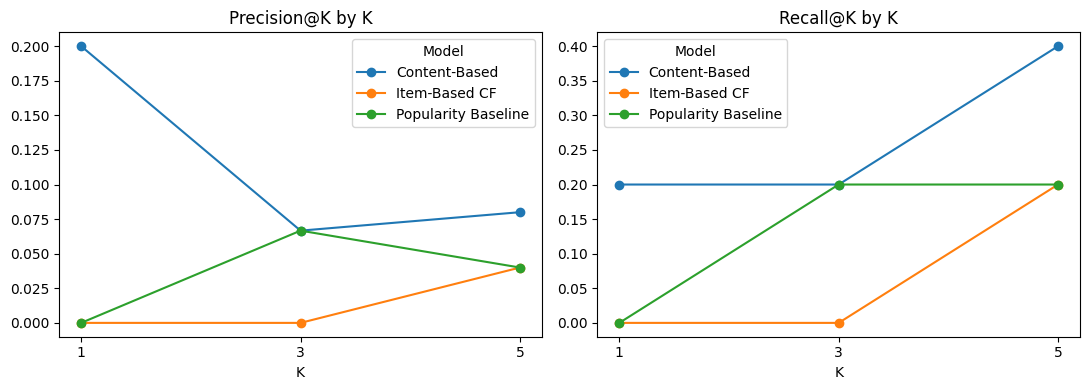

In [27]:
pivot = ext_results.pivot(index="K", columns="Model", values=["Precision@K", "Recall@K"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pivot["Precision@K"].plot(marker="o", ax=axes[0], title="Precision@K by K")
pivot["Recall@K"].plot(marker="o", ax=axes[1], title="Recall@K by K")
for ax in axes:
    ax.set_xticks([1, 3, 5])
plt.tight_layout()
plt.show()

**Explanation:** Every user here has only one held-out relevant movie, so at most one hit is possible per user. As K grows, Precision@K tends to fall (or stay low) because the denominator is K while there is still at most one hit, so the best possible precision drops from 1.0 at K=1 to 0.33 at K=3 and 0.20 at K=5. Recall@K tends to rise or stay the same as K grows, because a longer list gives more chances to include the one relevant item. We can see this for content-based, whose recall goes from 0.20 (K=1 and K=3) to 0.40 (K=5), while its precision drops from 0.20 at K=1 to about 0.07-0.08 at K=3 and K=5. Popularity only finds its hit from K=3 and CF only from K=5, which fits the idea that CF is good at predicting ratings but not at putting the right movie right at the top of the list.

## Final Summary
- **Best for rating prediction:** Item-Based CF (lowest MAE and RMSE).
- **Best for ranking:** Content-Based (found a hit and ranked it higher, NDCG@3 = 0.20), with the caveat that this rests on only 5 users.
- **Best for coverage, novelty and diversity:** Item-Based CF.
- **Recommended for the stated business objective:** Item-Based CF, ideally combined with content-based ranking in a real system.